# 06 · Covariance forecasts as hedging decisions

**RQ3:** Does a covariance estimate support a useful economic decision?
Keep one near contract and use the middle/far contracts as hedges. The objective
is reduced settlement risk, not an expected-return or trading-alpha strategy.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spde_covariance.empirical_research import load_research_evidence

evidence = load_research_evidence(Path("../experiments/results/shfe-research"))
print(evidence["protocol"]["status"])
print("Numerical source:", evidence["manifest"]["git_revision"])
print("Original baseline source:", evidence["protocol"]["baseline_source_revision"])
assert evidence["protocol"]["baseline_summary_sha256"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
LABELS = {
    "outright_3m": "Outright",
    "spread_3m_6m": "Spread",
    "butterfly_3m_6m_9m": "Butterfly",
    "factor": "Factor only",
    "joint": "Factor + residual",
    "source": "Source C (original)",
    "direct": "Direct",
    "unhedged": "Unhedged",
    "factor_adjusted": "Transport adjusted",
    "factor_unadjusted": "Unadjusted",
    "spde_local": "Local source C",
    "shrinkage": "Direct + shrinkage",
    "joint_calendar": "Joint / calendar",
    "joint_session": "Joint / session",
    "bootstrap_percentile_95": "95% block range",
    "bootstrap_standard_error": "Block SE",
    "realized_over_predicted_second_moment": "Realized / predicted",
    "predicted_rms_cny": "Forecast RMS (CNY)",
    "realized_rms_cny": "Realized RMS (CNY)",
    "mean_position_change_proxy": "Position-change proxy",
    "training_count_min_median_max": "Training count (min/median/max)",
    "minimum_relative_forecast_eigenvalue": "Min relative eigenvalue",
    "maximum_exact_transport_identity_absolute_error": "Max transport error",
    "all_forecast_psd_within_roundoff": "PSD within roundoff",
}


def readable_label(value):
    return LABELS.get(value, value.replace("_", " "))


def display_value(value):
    if value is None:
        return "Unavailable"
    if isinstance(value, float):
        return f"{value:.4g}"
    if isinstance(value, (list, tuple)):
        return "[" + ", ".join((display_value(v) for v in value)) + "]"
    if isinstance(value, dict):
        return "; ".join((f"{readable_label(k)}: {display_value(v)}" for k, v in value.items()))
    return readable_label(value) if isinstance(value, str) else str(value)


def table(rows, columns):
    cells = [[readable_label(c) for c in columns]] + [
        [display_value(r.get(c)) for c in columns] for r in rows
    ]
    widths = [max((len(row[i]) for row in cells)) for i in range(len(columns))]
    for row in cells:
        print(" | ".join((v.ljust(w) for v, w in zip(row, widths, strict=True))))

exploratory development on inspected 2024–2025 data
Numerical source: a2f99054886b3154a311665cee7cacd8e6af483c
Original baseline source: d284718c0e465d39886500ab2d85904183266747


## Decision problem and chronology

Given the issued PSD raw contract covariance $\widehat K_n$, solve

$$
\min_{h\in[-2,2]^2}(1,h^\top)\widehat K_n(1,h^\top)^\top.
$$

The solver checks the unconstrained stationary point, edges and corners, so
singular PSD controls remain well-defined. It receives no future price. Each
rule selects its risk-model settings on 2023 validation QLIKE, then issues
positions using data through the origin. The same actual contracts are held
until next session. These are risk-selected policies, not separately
hedging-loss-tuned policies.

In [2]:
joint = evidence["joint"]
print(joint["hedge_scope"])
print("Bounds:", joint["joint_config"]["hedge_bounds"])
primary_methods = ["direct", "joint", "source", "factor"]
rows = [
    next((r for r in joint["hedge_summary"] if r["method"] == method))
    for method in ["unhedged", *primary_methods]
]
table(
    rows,
    [
        "method",
        "common_count",
        "realized_rms_cny",
        "predicted_rms_cny",
        "realized_over_predicted_second_moment",
    ],
)

one near contract plus two bounded maturity-target positions, settlement P&L; turnover is a position-change proxy and excludes execution/roll costs
Bounds: [-2.0, 2.0]
method              | common count | Realized RMS (CNY) | Forecast RMS (CNY) | Realized / predicted
Unhedged            | 484          | 3487               | Unavailable        | Unavailable         
Direct              | 484          | 501.4              | 664.7              | 0.5691              
Factor + residual   | 484          | 533                | 666.5              | 0.6395              
Source C (original) | 484          | 624.1              | 312.9              | 3.978               
Factor only         | 484          | 684.9              | 303.2              | 5.103               


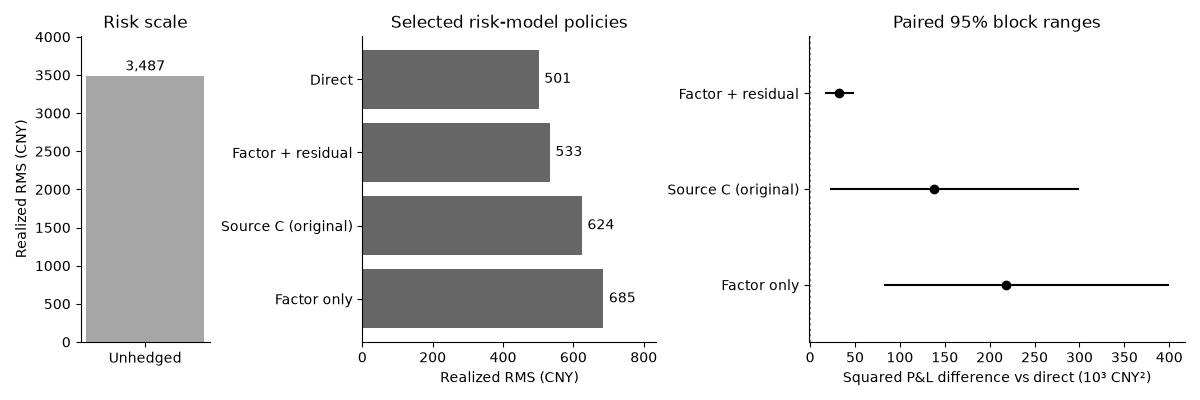

In [3]:
unhedged = rows[0]
hedged = rows[1:]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), gridspec_kw={"width_ratios": [1.1, 2.5, 3.2]})
axes[0].bar([0], [unhedged["realized_rms_cny"]], color="0.65", width=0.55)
axes[0].set(xticks=[0], xticklabels=["Unhedged"], ylabel="Realized RMS (CNY)", title="Risk scale")
axes[0].annotate(
    f"{unhedged['realized_rms_cny']:,.0f}",
    (0, unhedged["realized_rms_cny"]),
    xytext=(0, 4),
    textcoords="offset points",
    ha="center",
)
axes[0].margins(y=0.15)
axes[1].barh(range(len(hedged)), [r["realized_rms_cny"] for r in hedged], color="0.4")
axes[1].set(
    yticks=range(len(hedged)),
    yticklabels=[readable_label(r["method"]) for r in hedged],
    xlabel="Realized RMS (CNY)",
    title="Selected risk-model policies",
)
axes[1].invert_yaxis()
axes[1].margins(x=0.22)
for i, r in enumerate(hedged):
    axes[1].annotate(
        f"{r['realized_rms_cny']:.0f}",
        (r["realized_rms_cny"], i),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
    )
differences = [
    next((r for r in joint["hedge_paired"] if r["method"] == method and r["reference"] == "direct"))
    for method in primary_methods
    if method != "direct"
]
for i, r in enumerate(differences):
    lo, hi = np.asarray(r["bootstrap_percentile_95"]) / 1000.0
    axes[2].plot([lo, hi], [i, i], color="black", linewidth=1.5)
    axes[2].plot(r["mean"] / 1000.0, i, "o", color="black")
axes[2].axvline(0, color="0.5", linestyle=":")
axes[2].set(
    yticks=range(len(differences)),
    yticklabels=[readable_label(r["method"]) for r in differences],
    xlabel="Squared P&L difference vs direct (10³ CNY²)",
    title="Paired 95% block ranges",
)
axes[2].invert_yaxis()
axes[2].margins(y=0.3)
fig.tight_layout()
plt.show()

## Paired realized risk and position stability

The unhedged and hedged RMS panels use different scales. The primary comparison
shows four validation-selected policies; duplicate calendar companions and
fixed-clock sensitivities remain in the full aggregate file. The source-$C$
rule uses its own selected 252-interval coefficient history; the other selected
rules use 63-interval windows on common current-contract support. These are
whole-policy comparisons, not an isolated test of a single model mechanism.

All displayed rules use the common scored-origin cohort. Negative paired
squared-P&L differences favor the listed rule. Bootstrap blocks resample
paired sessions, not independent strategies. Mean hedge positions and bound
hits help detect unstable optimization even when average risk is small. The
intervals are descriptive, conditional on this inspected development sample;
they do not adjust for model development or multiple comparisons. RMS bars
are point summaries; uncertainty is shown for paired squared-P&L differences.

All 11 policies, sensitivity results and full availability counts are retained
in [the joint risk / hedge aggregate](../experiments/results/shfe-research/joint.json).

In [4]:
table(
    [
        r
        for r in joint["hedge_paired"]
        if r["method"] in primary_methods and r["reference"] in ("unhedged", "direct")
    ],
    ["method", "reference", "count", "mean", "bootstrap_standard_error", "bootstrap_percentile_95"],
)
table(
    hedged, ["method", "mean_hedge_positions", "bound_hit_fraction", "mean_position_change_proxy"]
)
table(
    [{"method": method, **joint["availability"][method]} for method in primary_methods],
    ["method", "attempted", "issued", "fully_scored", "hedge_scored"],
)
assert len({r["common_count"] for r in rows}) == 1

method              | reference | count | mean       | Block SE  | 95% block range         
Direct              | Unhedged  | 484   | -1.191e+07 | 2.24e+06  | [-1.633e+07, -7.702e+06]
Factor only         | Unhedged  | 484   | -1.169e+07 | 2.198e+06 | [-1.605e+07, -7.57e+06] 
Factor only         | Direct    | 484   | 2.177e+05  | 8.313e+04 | [8.331e+04, 3.985e+05]  
Factor + residual   | Unhedged  | 484   | -1.188e+07 | 2.24e+06  | [-1.63e+07, -7.676e+06] 
Factor + residual   | Direct    | 484   | 3.266e+04  | 8001      | [1.754e+04, 4.761e+04]  
Source C (original) | Unhedged  | 484   | -1.177e+07 | 2.215e+06 | [-1.62e+07, -7.619e+06] 
Source C (original) | Direct    | 484   | 1.381e+05  | 7.599e+04 | [2.35e+04, 2.982e+05]   
method              | mean hedge positions | bound hit fraction | Position-change proxy
Direct              | [-0.6739, -0.3295]   | 0                  | 0.0541               
Factor + residual   | [-0.5294, -0.4776]   | 0                  | 0.06438              


## Interpretation and next decision

Realized RMS is CNY 3,487 unhedged, 501 with direct covariance, 533 with joint
factor/residual, 624 with the original source model and 685 with factor-only.
Joint minus direct squared P&L averages +32,657 CNY², with descriptive bootstrap
range [17,545, 47,609]; direct has lower realized risk in this sample.

This closes the pipeline from data and curve reconstruction to model risk and
a constrained decision. It does not establish an executable backtest: contract
switching, actual fills, margin, roll mechanics, transaction costs and liquidity
capacity are not modeled. A later execution-aware study needs these inputs and
an uninspected evaluation period. Do not turn lower settlement RMS alone into
a profitability or CV performance claim.

## Reproduction and research boundary

This notebook reads checksummed aggregate evidence, not raw exchange files.
The numerical algorithms are in `spde_covariance`; use the
[protocol](../docs/empirical-research-protocol.md) to rerun local calibration.
Execute this notebook with `uv run python scripts/check_notebook.py notebooks/06_hedging_decisions.ipynb`.

The original historical benchmark remains fixed. New analyses on the inspected
2024–2025 period are exploratory, even though forecast issuance is past-only.
No final untouched confirmation period, executable trading backtest or physical
forcing identification is claimed. See the [roadmap](../README.md).

The displayed tables emphasize the primary comparisons. Complete sensitivity,
availability and numerical diagnostics remain in the checksummed aggregate files:
[data](../experiments/results/shfe-research/data.json),
[representation](../experiments/results/shfe-research/representation.json),
[attribution](../experiments/results/shfe-research/attribution.json),
[scores](../experiments/results/shfe-research/scores.json), and
[joint risk / hedging](../experiments/results/shfe-research/joint.json).